In [179]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder,LabelEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import ConfusionMatrixDisplay,f1_score,recall_score,precision_score,accuracy_score

In [180]:
data={
    "age_rank":["youth","youth","mediate","older","older","mediate","youth","youth","older","youth","mediate","mediate","older","older","youth","youth","mediate"],
    "income_rank":["high","high","high","medium","low","low","low","medium","low","medium","medium","high","high","low","low","medium","high"],
    "student":["no","no","no","no","yes","yes","yes","no","yes","yes","yes","no","no","no","yes","yes","yes"],
    "credit_rating":["fair","excellent","fair","fair","excellent","excellent","fair","fair","excellent","fair","fair","fair","excellent","excellent","fair","excellent","fair"],
    "buys_computer":["no","no","yes","yes","yes","no","yes","no","yes","yes","yes","no","yes","yes","yes","no","yes"]
}

In [181]:
for key in data:
    print(f"{key}: {len(data[key])}")
    print(set(data[key]))

age_rank: 17
{'youth', 'mediate', 'older'}
income_rank: 17
{'high', 'low', 'medium'}
student: 17
{'no', 'yes'}
credit_rating: 17
{'fair', 'excellent'}
buys_computer: 17
{'no', 'yes'}


In [182]:
data=pd.DataFrame(data)
data

,age_rank,income_rank,student,credit_rating,buys_computer
0,youth,high,no,fair,no
1,youth,high,no,excellent,no
2,mediate,high,no,fair,yes
3,older,medium,no,fair,yes
4,older,low,yes,excellent,yes
5,mediate,low,yes,excellent,no
6,youth,low,yes,fair,yes
7,youth,medium,no,fair,no
8,older,low,yes,excellent,yes
9,youth,medium,yes,fair,yes


In [183]:
features=data.drop(columns="buys_computer")
target=data["buys_computer"]

In [184]:
# encode target
encoder=LabelEncoder()
target=encoder.fit_transform(target)

In [185]:
# split dataset into training and testing dataset
x_train,x_test,y_train,y_test=train_test_split(
    features,
    target,
    test_size=7,
    random_state=45,
    stratify=target
)

In [186]:
model=Pipeline(steps=[
        ("encoder",OrdinalEncoder()),
        ("model",CategoricalNB(alpha=1))
    ])

In [187]:
x_train.shape

(10, 4)

In [188]:
y_train.shape

(10,)

In [189]:
# train
model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('encoder', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute.",'auto'
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'use_encoded_value'}, default='error'When set to 'error' an error will be raised in case an unknowncategorical feature is present during transform. When set to'use_encoded_value', the encoded value of unknown categories will beset to the value given for the parameter `unknown_value`. In:meth:`inverse_transform`, an unknown category will be denoted as None... versionadded:: 0.24",'error'
,"unknown_value unknown_value: int or np.nan, default=NoneWhen the parameter handle_unknown is set to 'use_encoded_value', thisparameter is required and will set the encoded value of unknowncategories. It has to be distinct from the values used to encode any ofthe categories in `fit`. If set to np.nan, the `dtype` parameter mustbe a float dtype... versionadded:: 0.24",None
,"encoded_missing_value encoded_missing_value: int or np.nan, default=np.nanEncoded value of missing categories. If set to `np.nan`, then the `dtype`parameter must be a float dtype... versionadded:: 1.1",nan
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.3 Read more in the :ref:`User Guide `.",None
,"max_categories max_categories: int, default=NoneSpecifies an upper limit to the number of output categories for each inputfeature when considering infrequent categories. If there are infrequentcategories, `max_categori

In [190]:
y_train_predict=model.predict(x_train)

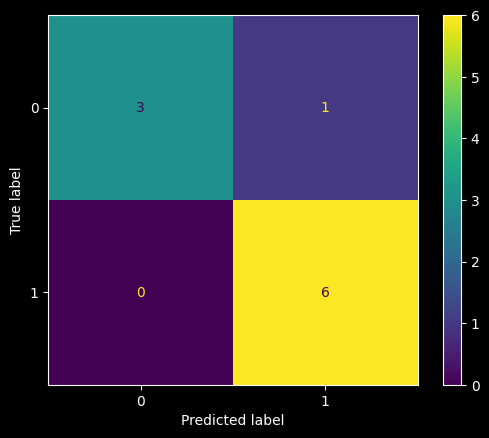

In [191]:
# Confusion_matrix
conf_train=ConfusionMatrixDisplay.from_predictions(y_train,y_train_predict)

In [192]:
print(f"""accuracy: {round(accuracy_score(y_train,y_train_predict),4)}
recall: {round(recall_score(y_train,y_train_predict),4)}
precision: {round(precision_score(y_train,y_train_predict),4)}
f_1: {round(f1_score(y_train,y_train_predict),4)}""")

accuracy: 0.9
recall: 1.0
precision: 0.8571
f_1: 0.9231


In [193]:
# test
y_test_predict=model.predict(x_test)

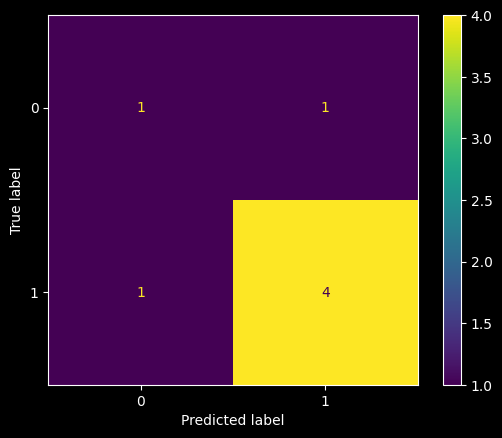

In [194]:
# Confusion_matrix
conf_train=ConfusionMatrixDisplay.from_predictions(y_test,y_test_predict)

In [195]:
print(f"""accuracy: {round(accuracy_score(y_test,y_test_predict),4)}
recall: {round(recall_score(y_test,y_test_predict),4)}
precision: {round(precision_score(y_test,y_test_predict),4)}
f_1: {round(f1_score(y_test,y_test_predict),4)}""")

accuracy: 0.7143
recall: 0.8
precision: 0.8
f_1: 0.8
